# GameTheory-03-Topology2x2-Python

**Navigation** : [<< 2-NormalForm](GameTheory-02-NormalForm-Python.ipynb) | [Index](README.md) | [4-NashEquilibrium >>](GameTheory-04-NashEquilibrium-Python.ipynb) | [Greffe N-personnes : Dynamics-09](Dynamics/Dynamics-09-Biens-Publics-N-Personnes-Python.ipynb)

## Topologie et Classification des Jeux 2x2

Ce notebook explore la **structure topologique** des jeux 2x2, basee sur les travaux de Robinson & Goforth (2005).

### Objectifs d'apprentissage

1. Comprendre la classification des jeux 2x2 (144 jeux uniques)
2. Explorer la "table periodique" des jeux stratégiques
3. Visualiser les transformations entre jeux par swap de gains
4. Identifier les familles de jeux : PD, Stag Hunt, Chicken, Battle of Sexes
5. Comprendre la structure torique de l'espace des jeux
6. Dériver le quotient à 144 classes et le 78 de Rapoport-Guyer — pas les recopier

### Prerequis

- Notebooks 1-2 : Fondations et jeux en forme normale
- Notion de gain ordinal et de matrice de gains

### Duree estimee : 80 minutes

### References
- Robinson & Goforth (2005) - "The Topology of the 2x2 Games"
- Rapoport & Guyer (1966) - "A Taxonomy of 2x2 Games"

## Références

**Osborne & Rubinstein (1994)**, ch. 2 « Nash Equilibrium », §2.1-2.3 (Strategic Games, equilibre, exemples types) : la grille de lecture des 12 topologies 2x2 ordinales. Condense : **Leyton-Brown & Shoham (2008)**, ch. 1 §1.3 puis ch. 2 « From Optimality To Equilibrium ». Gisement cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\`.


In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LinearSegmentedColormap
import networkx as nx
from typing import List, Tuple, Dict, Set
from itertools import permutations
from dataclasses import dataclass
import warnings
warnings.filterwarnings('ignore')
print("Imports OK : numpy, matplotlib")


Imports OK : numpy, matplotlib


### Configuration de l'environnement

Nous importons les bibliothèques nécessaires pour :
- **Numpy** : manipulation de matrices de gains
- **Matplotlib** : visualisations graphiques
- **NetworkX** : représentation du graphe de transformations
- **dataclasses** : structure de données pour les jeux
- **itertools.permutations** : génération de toutes les permutations ordinales

## 1. Representation ordinale des jeux 2x2

### Notation ordinale

Pour classifier les jeux 2x2, on utilise une representation **ordinale** plutot que cardinale.

Chaque joueur a 4 issues possibles, classees de 1 (pire) a 4 (meilleure) :
- 4 = meilleur résultat
- 3 = second meilleur
- 2 = second pire
- 1 = pire résultat

### Nombre de jeux

- Chaque joueur peut assigner les rangs 1,2,3,4 aux 4 cellules : $4! = 24$ facons
- Deux joueurs : $24 \times 24 = 576$ matrices
- En eliminant les equivalences stratégiques : **144 jeux distincts**
- En eliminant les symetries (echanger joueurs) : **78 classes**

### Pourquoi la représentation ordinale ?

La représentation **ordinale** (rangs 1-4) plutôt que **cardinale** (gains numériques arbitraires) présente plusieurs avantages :

**Avantages** :
1. **Indépendance des échelles** : Seul l'ordre des préférences compte, pas les valeurs absolues
2. **Classification exhaustive** : Permet d'énumérer tous les jeux possibles (24×24 = 576)
3. **Équivalence stratégique** : Deux jeux avec les mêmes rangs ont la même structure stratégique

**Exemple** : 
- Jeu A : gains (10, 5, 20, 15)
- Jeu B : gains (2, 1, 4, 3)

Ces deux jeux sont **stratégiquement identiques** car ils ont le même ordre ordinal : (2, 1, 4, 3).

> **Note** : Cette approche suppose que les joueurs sont **ordinaux** dans leurs préférences, c'est-à-dire qu'ils se soucient uniquement de l'ordre, pas de l'intensité des différences.

In [2]:
@dataclass
class OrdinalGame:
    """
    Jeu 2x2 en representation ordinale.
    
    Chaque matrice contient les rangs 1-4 pour les 4 cellules.
    Convention: cellules numerotees comme suit:
        0 | 1
        -----
        2 | 3
    """
    row_payoffs: Tuple[int, int, int, int]  # Gains ordinaux du joueur Ligne
    col_payoffs: Tuple[int, int, int, int]  # Gains ordinaux du joueur Colonne
    name: str = ""
    
    def __post_init__(self):
        # Verifier que c'est bien une permutation de (1,2,3,4)
        assert sorted(self.row_payoffs) == [1, 2, 3, 4], "row_payoffs doit etre permutation de 1-4"
        assert sorted(self.col_payoffs) == [1, 2, 3, 4], "col_payoffs doit etre permutation de 1-4"
    
    def to_matrices(self) -> Tuple[np.ndarray, np.ndarray]:
        """Convertit en matrices 2x2."""
        A = np.array([[self.row_payoffs[0], self.row_payoffs[1]],
                      [self.row_payoffs[2], self.row_payoffs[3]]])
        B = np.array([[self.col_payoffs[0], self.col_payoffs[1]],
                      [self.col_payoffs[2], self.col_payoffs[3]]])
        return A, B
    
    def display(self):
        """Affiche le jeu."""
        A, B = self.to_matrices()
        print(f"\n{self.name if self.name else 'Jeu'}")
        print("="*30)
        print(f"      C0        C1")
        print(f"R0  ({A[0,0]},{B[0,0]})    ({A[0,1]},{B[0,1]})")
        print(f"R1  ({A[1,0]},{B[1,0]})    ({A[1,1]},{B[1,1]})")
    
    def __hash__(self):
        return hash((self.row_payoffs, self.col_payoffs))
    
    def __eq__(self, other):
        return self.row_payoffs == other.row_payoffs and self.col_payoffs == other.col_payoffs

# Exemple: Dilemme du Prisonnier en ordinal
# Convention standard: (C,C)=3, (C,D)=1, (D,C)=4, (D,D)=2
pd = OrdinalGame(
    row_payoffs=(3, 1, 4, 2),  # C coopere: 3 vs C, 1 vs D; Row defait: 4 vs C, 2 vs D
    col_payoffs=(3, 4, 1, 2),  # Symetrique
    name="Prisonnier Dilemma"
)
pd.display()


Prisonnier Dilemma
      C0        C1
R0  (3,3)    (1,4)
R1  (4,1)    (2,2)


## 2. Jeux classiques en representation ordinale

Definissons les jeux classiques avec leur structure de gains ordinale.

In [3]:
# Collection de jeux classiques en ordinal

CLASSIC_GAMES = {
    # Dilemme du Prisonnier
    # Tentatin (DC) > Reward (CC) > Punishment (DD) > Sucker (CD)
    "Prisoner's Dilemma": OrdinalGame(
        row_payoffs=(3, 1, 4, 2),
        col_payoffs=(3, 4, 1, 2),
        name="Prisoner's Dilemma"
    ),
    
    # Stag Hunt (Chasse au cerf)
    # (C,C) meilleur (4) > (D,C) (3) > (D,D) (2) > (C,D) pire (1)
    # Construction choisie : PD -> Stag Hunt en 2 swaps (section 3)
    "Stag Hunt": OrdinalGame(
        row_payoffs=(4, 1, 3, 2),
        col_payoffs=(4, 3, 1, 2),
        name="Stag Hunt"
    ),
    
    # Battle of the Sexes
    # Preferred coordination > Other coordination > Miscoordination
    "Battle of Sexes": OrdinalGame(
        row_payoffs=(4, 1, 2, 3),
        col_payoffs=(3, 2, 1, 4),
        name="Battle of Sexes"
    ),
    
    # Chicken / Hawk-Dove
    # Exploit > Compromise > Yield > Crash
    "Chicken": OrdinalGame(
        row_payoffs=(3, 2, 4, 1),
        col_payoffs=(3, 4, 2, 1),
        name="Chicken (Hawk-Dove)"
    ),
    
    # Matching Pennies
    # Win > Lose (alternating)
    "Matching Pennies": OrdinalGame(
        row_payoffs=(4, 1, 2, 3),
        col_payoffs=(1, 4, 3, 2),
        name="Matching Pennies"
    ),
    
    # Pure Coordination
    # Match > Mismatch
    "Pure Coordination": OrdinalGame(
        row_payoffs=(4, 1, 2, 3),
        col_payoffs=(4, 2, 1, 3),
        name="Pure Coordination"
    ),
    
    # Deadlock
    # Defect is dominant and Pareto optimal
    "Deadlock": OrdinalGame(
        row_payoffs=(2, 1, 4, 3),
        col_payoffs=(2, 4, 1, 3),
        name="Deadlock"
    ),
    
    # Harmony
    # Cooperate is dominant
    "Harmony": OrdinalGame(
        row_payoffs=(4, 3, 2, 1),
        col_payoffs=(4, 2, 3, 1),
        name="Harmony"
    ),
}

# Afficher tous les jeux
for name, game in CLASSIC_GAMES.items():
    game.display()


Prisoner's Dilemma
      C0        C1
R0  (3,3)    (1,4)
R1  (4,1)    (2,2)

Stag Hunt
      C0        C1
R0  (4,4)    (1,3)
R1  (3,1)    (2,2)

Battle of Sexes
      C0        C1
R0  (4,3)    (1,2)
R1  (2,1)    (3,4)

Chicken (Hawk-Dove)
      C0        C1
R0  (3,3)    (2,4)
R1  (4,2)    (1,1)

Matching Pennies
      C0        C1
R0  (4,1)    (1,4)
R1  (2,3)    (3,2)

Pure Coordination
      C0        C1
R0  (4,4)    (1,2)
R1  (2,1)    (3,3)

Deadlock
      C0        C1
R0  (2,2)    (1,4)
R1  (4,1)    (3,3)

Harmony
      C0        C1
R0  (4,4)    (3,2)
R1  (2,3)    (1,1)


### Observations sur les jeux classiques

Après avoir affiché tous les jeux classiques, notons plusieurs patterns :

**Symétrie** :
- PD, Stag Hunt, Pure Coordination sont **symétriques** (mêmes préférences pour Row et Col)
- Battle of Sexes, Matching Pennies sont **asymétriques**

**Position du meilleur résultat (4)** :
- **Diagonale** (cells 0 ou 3) : Stag Hunt, Pure Coordination → jeux de même côté
- **Hors diagonale** (cells 1 ou 2) : PD, Chicken → jeux d'exploitation mutuelle
- **Distribution** : Battle of Sexes (coins opposés) → jeux de préférence opposée

**Équilibres visibles** :
- PD, Deadlock : un seul équilibre (coin inférieur droit)
- Stag Hunt, Battle of Sexes, Pure Coordination : deux équilibres sur la diagonale
- Chicken : deux équilibres hors diagonale
- Matching Pennies : aucun équilibre pur (conflit pur)

### Lecture de la representation ordinale

Comment interpreter ces matrices ?

**Exemple du Dilemme du Prisonnier** :
```
      C0 (Coop)    C1 (Defect)
R0   (3,3)        (1,4)
R1   (4,1)        (2,2)
```

- **(3,3)** en haut-gauche : Si les deux cooperent, chacun obtient son 3eme meilleur résultat
- **(1,4)** en haut-droit : Si Row coopere et Col defait, Row obtient son PIRE (1) et Col son MEILLEUR (4)
- **(4,1)** : Symetrique - Row exploite Col
- **(2,2)** : Defection mutuelle - second pire pour les deux

**Observation cle** : La tentation de defaire (4 > 3) domine la cooperation, mais la defection mutuelle (2,2) est pire que la cooperation mutuelle (3,3). C'est le coeur du dilemme !

**Stag Hunt vs PD** : Notez que dans Stag Hunt, **(4,4)** est en haut-gauche - la cooperation mutuelle est le MEILLEUR résultat, pas juste "bon". Cela change fondamentalement la dynamique du jeu.

## 3. Swaps de gains : transformations elementaires

### Swaps adjacents

Un **swap** est l'echange de deux rangs adjacents (ex: 3 et 4, ou 1 et 2).

Pour chaque joueur, il y a 3 swaps possibles :
- Swap 3-4 : echange des deux meilleurs résultats
- Swap 2-3 : echange des résultats intermediaires
- Swap 1-2 : echange des deux pires résultats

Ces swaps forment la base des **transformations topologiques** entre jeux.

In [4]:
def swap_payoffs(payoffs: Tuple[int, int, int, int], 
                 rank1: int, rank2: int) -> Tuple[int, int, int, int]:
    """
    Echange deux rangs dans les gains.
    
    Args:
        payoffs: Tuple de gains ordinaux
        rank1, rank2: Rangs a echanger (ex: 3, 4)
    
    Returns:
        Nouveaux gains avec les rangs echanges
    """
    result = list(payoffs)
    for i in range(4):
        if result[i] == rank1:
            result[i] = rank2
        elif result[i] == rank2:
            result[i] = rank1
    return tuple(result)

def apply_row_swap(game: OrdinalGame, rank1: int, rank2: int) -> OrdinalGame:
    """Applique un swap aux gains du joueur Ligne."""
    new_row = swap_payoffs(game.row_payoffs, rank1, rank2)
    return OrdinalGame(new_row, game.col_payoffs)

def apply_col_swap(game: OrdinalGame, rank1: int, rank2: int) -> OrdinalGame:
    """Applique un swap aux gains du joueur Colonne."""
    new_col = swap_payoffs(game.col_payoffs, rank1, rank2)
    return OrdinalGame(game.row_payoffs, new_col)

# Exemple: Transformer le Dilemme du Prisonnier
pd = CLASSIC_GAMES["Prisoner's Dilemma"]
print("Jeu original:")
pd.display()

# Swap 3-4 pour le joueur Ligne
pd_swap34_row = apply_row_swap(pd, 3, 4)
print("\nApres swap 3-4 pour Ligne:")
pd_swap34_row.display()

print("\nInterpretation: Maintenant (C,C) est prefere a (D,C) pour Ligne")
print("-> Le jeu devient plus cooperatif pour Ligne")

Jeu original:

Prisoner's Dilemma
      C0        C1
R0  (3,3)    (1,4)
R1  (4,1)    (2,2)

Apres swap 3-4 pour Ligne:

Jeu
      C0        C1
R0  (4,3)    (1,4)
R1  (3,1)    (2,2)

Interpretation: Maintenant (C,C) est prefere a (D,C) pour Ligne
-> Le jeu devient plus cooperatif pour Ligne


### Recherche de chemins par BFS

La fonction `find_swap_path()` utilise un parcours en largeur (BFS) pour trouver le **chemin le plus court** entre deux jeux.

**Algorithme** :
1. Départ : jeu initial dans la queue
2. À chaque étape : explorer tous les voisins (6 swaps possibles)
3. Marquer les jeux visités pour éviter les cycles
4. Arrêt : quand on atteint le jeu cible

**Complexité** : 
- Espace : O(576) = tous les jeux possibles
- Temps : O(6 × 576) = exploration des arêtes

Le résultat montre que PD et Stag Hunt ne sont distants que de **2 swaps**, confirmant leur proximité structurelle.

In [5]:
def find_swap_path(game1: OrdinalGame, game2: OrdinalGame) -> List[str]:
    """
    Trouve une sequence de swaps transformant game1 en game2.
    
    Returns:
        Liste de swaps au format "ROW_3-4" ou "COL_2-3"
    """
    from collections import deque
    
    # BFS pour trouver le chemin le plus court
    queue = deque([(game1, [])])
    visited = {game1}
    
    swaps = [(3, 4), (2, 3), (1, 2)]
    
    while queue:
        current, path = queue.popleft()
        
        if current == game2:
            return path
        
        # Essayer tous les swaps possibles
        for r1, r2 in swaps:
            # Swap pour Row
            new_game = apply_row_swap(current, r1, r2)
            if new_game not in visited:
                visited.add(new_game)
                queue.append((new_game, path + [f"ROW_{r1}-{r2}"]))
            
            # Swap pour Col
            new_game = apply_col_swap(current, r1, r2)
            if new_game not in visited:
                visited.add(new_game)
                queue.append((new_game, path + [f"COL_{r1}-{r2}"]))
    
    return None  # Pas de chemin (ne devrait pas arriver)

# Transformer Prisoner's Dilemma en Stag Hunt
pd = CLASSIC_GAMES["Prisoner's Dilemma"]
sh = CLASSIC_GAMES["Stag Hunt"]

path = find_swap_path(pd, sh)
print("Transformation: Prisoner's Dilemma -> Stag Hunt")
print(f"Swaps necessaires: {path}")

# Appliquer pas a pas
current = pd
print("\nEtapes:")
current.display()

for swap in path:
    parts = swap.split("_")
    player = parts[0]
    ranks = parts[1].split("-")
    r1, r2 = int(ranks[0]), int(ranks[1])
    
    if player == "ROW":
        current = apply_row_swap(current, r1, r2)
    else:
        current = apply_col_swap(current, r1, r2)
    
    print(f"\nApres {swap}:")
    current.display()

Transformation: Prisoner's Dilemma -> Stag Hunt
Swaps necessaires: ['ROW_3-4', 'COL_3-4']

Etapes:

Prisoner's Dilemma
      C0        C1
R0  (3,3)    (1,4)
R1  (4,1)    (2,2)

Apres ROW_3-4:

Jeu
      C0        C1
R0  (4,3)    (1,4)
R1  (3,1)    (2,2)

Apres COL_3-4:

Jeu
      C0        C1
R0  (4,4)    (1,3)
R1  (3,1)    (2,2)


### Interpretation de la transformation PD -> Stag Hunt

Les swaps `ROW_3-4` et `COL_3-4` transforment le Dilemme du Prisonnier en Stag Hunt. Mais que signifie cela conceptuellement ?

**Swap 3-4** = "Echanger les deux meilleurs résultats"

- **Avant (PD)** : Le meilleur résultat est d'exploiter l'autre (defaire quand l'autre coopere)
- **Après (Stag Hunt)** : Le meilleur résultat est la cooperation mutuelle

**Interpretation economique** :
- Dans le PD, les gains de l'exploitation sont superieurs aux gains de la cooperation
- Après le swap, cooperer ensemble devient PLUS attrayant qu'exploiter

**Exemple concret** :
- **PD** : Je prefere voler mon voisin (4) plutot que cooperer avec lui (3)
- **Stag Hunt** : Je prefere chasser le cerf ensemble (4) plutot que voler le lievre de mon voisin (3)

C'est un changement fondamental dans la structure des incitations !

### 11.1. Exercice 1 : Voisins de swap d'un jeu personnalise

Créez un jeu 2x2 ordinal de votre choix et explorez ses **6 voisins** dans le graphe des swaps. Pour chaque voisin, identifiez sa **famille** (DOMINANT / COORDINATION / ANTI_COORDINATION / MIXED_ONLY / SINGLE_NASH) et ses **equilibres de Nash**. Comparez avec votre jeu de depart : quels swaps transforment la structure stratégique ?

**Contexte pedagogique** : Les 6 voisins representent toutes les **transformations elementaires** (swap adjacent 1-2, 2-3, 3-4 pour chaque joueur). Explorer le voisinage d'un jeu personnel revele sa "place" dans l'espace topologique des 576 jeux 2x2.

**Indice 1 (construction de l'espace de recherche)** : 
- Pour créer un jeu original : `OrdinalGame(row_payoffs=(2, 4, 1, 3), col_payoffs=(1, 3, 4, 2), name="MonJeu")` — chaque tuple doit etre une permutation de (1, 2, 3, 4)
- Pour verifier sa validite : la classe `OrdinalGame` leve une `AssertionError` si les tuples ne sont pas des permutations valides

**Indice 2 (generation exhaustive des voisins)** :
- Les **6 voisins** s'obtiennent en appliquant chaque swap a chaque joueur : 
  - `apply_row_swap(game, 1, 2)`, `apply_row_swap(game, 2, 3)`, `apply_row_swap(game, 3, 4)` (3 voisins pour Ligne)
  - `apply_col_swap(game, 1, 2)`, `apply_col_swap(game, 2, 3)`, `apply_col_swap(game, 3, 4)` (3 voisins pour Colonne)

**Indice 3 (analyse structurelle et comparaison)** :
- Pour chaque voisin, utilisez `classify_game_family(voisin)` et `find_pure_nash(voisin)` pour le decrire
- Pour la comparaison : `voisin.row_payoffs != game.row_payoffs` detecte si le swap affecte Ligne ou Colonne
- Pattern de sortie : liste de dicts `[{"swap": "ROW_3-4", "family": "COORDINATION", "nash": [(0,0), (1,1)]}, ...]`

In [6]:
def explore_swap_neighbors(game: OrdinalGame) -> list:
    # TODO etudiant : implementer l'exploration des voisins de swap
    # Etape 1 : iterer sur les 3 paires de swaps [(1,2), (2,3), (3,4)]
    # Etape 2 : pour chaque paire, calculer le voisin Row et le voisin Col
    # Etape 3 : pour chaque voisin, determiner sa famille et ses equilibres de Nash
    # Etape 4 : retourner une liste de dicts avec les informations de chaque voisin
    # Indice : utilisez apply_row_swap, apply_col_swap, classify_game_family, find_pure_nash
    return []  # TODO etudiant : remplacer

# mon_jeu = OrdinalGame(row_payoffs=(2, 4, 1, 3), col_payoffs=(1, 3, 4, 2), name="MonJeu")
# resultats = explore_swap_neighbors(mon_jeu)
print("Exercice a completer : exploration des voisins de swap")

Exercice a completer : exploration des voisins de swap


## 4. Graphe des transformations

Les jeux 2x2 forment un **graphe** ou :
- Chaque noeud est un jeu
- Chaque arete represente un swap adjacent

Ce graphe a une structure **torique** remarquable.

### Le graphe des jeux comme espace topologique

Au lieu de voir les jeux 2x2 comme un ensemble isolé de 576 cas séparés, Robinson & Goforth proposent de les voir comme formant un **espace topologique continu**.

**Métaphore** : Imaginez chaque jeu comme une ville, et chaque swap comme une route entre villes voisines. L'ensemble forme un réseau de villes connectées.

**Questions intéressantes** :
- Quelle est la distance entre deux jeux ? (nombre minimal de swaps)
- Existe-t-il des "régions" dans cet espace ? (groupes de jeux similaires)
- Le graphe a-t-il une structure géométrique particulière ? (spoiler: oui, c'est un tore !)

In [7]:
def generate_all_ordinal_games() -> Set[OrdinalGame]:
    """
    Genere tous les jeux 2x2 en representation ordinale.
    
    Returns:
        Ensemble de 576 jeux (avant elimination des equivalences)
    """
    games = set()
    
    for row_perm in permutations([1, 2, 3, 4]):
        for col_perm in permutations([1, 2, 3, 4]):
            games.add(OrdinalGame(row_perm, col_perm))
    
    return games

all_games = generate_all_ordinal_games()
print(f"Nombre total de jeux ordinaux: {len(all_games)}")
print(f"(24 permutations Row x 24 permutations Col = 576)")

Nombre total de jeux ordinaux: 576
(24 permutations Row x 24 permutations Col = 576)


### Interpretation : Generation exhaustive

La fonction genere les **576 jeux 2x2 possibles** en representation ordinale.

**Calcul combinatoire** :
- Joueur Ligne : 4! = 24 facons d'assigner les rangs 1-4 aux 4 cellules
- Joueur Colonne : 4! = 24 facons independantes
- Total : 24 x 24 = **576 jeux**

**Reduction par equivalence** :
Les 576 jeux se reduisent a :
- **144 jeux distincts** après elimination des equivalences stratégiques (permutation des stratégies)
- **78 classes** après elimination de la symetrie entre joueurs (echanger Row et Col)

> **Note** : Nous travaillons avec les 576 pour avoir le graphe complet. Les 144 jeux distincts correspondent aux "noyaux" de Robinson & Goforth.

In [8]:
def build_swap_graph(games: Set[OrdinalGame]) -> nx.Graph:
    """
    Construit le graphe des swaps entre jeux.
    
    Chaque arete represente un swap adjacent pour un joueur.
    """
    G = nx.Graph()
    
    # Ajouter tous les jeux comme noeuds
    game_list = list(games)
    for i, g in enumerate(game_list):
        G.add_node(i, game=g)
    
    # Indexer par representation
    game_to_idx = {g: i for i, g in enumerate(game_list)}
    
    # Ajouter les aretes (swaps)
    swaps = [(3, 4), (2, 3), (1, 2)]
    
    for i, g in enumerate(game_list):
        for r1, r2 in swaps:
            # Swap Row
            neighbor = apply_row_swap(g, r1, r2)
            if neighbor in game_to_idx:
                j = game_to_idx[neighbor]
                G.add_edge(i, j, swap=f"R{r1}{r2}")
            
            # Swap Col
            neighbor = apply_col_swap(g, r1, r2)
            if neighbor in game_to_idx:
                j = game_to_idx[neighbor]
                G.add_edge(i, j, swap=f"C{r1}{r2}")
    
    return G, game_list

# Construire le graphe complet
G_full, game_list = build_swap_graph(all_games)

print(f"Graphe des jeux:")
print(f"  Noeuds (jeux): {G_full.number_of_nodes()}")
print(f"  Aretes (swaps): {G_full.number_of_edges()}")
print(f"  Degre moyen: {2 * G_full.number_of_edges() / G_full.number_of_nodes():.1f}")
print(f"  (Chaque jeu a 6 voisins: 3 swaps x 2 joueurs)")

Graphe des jeux:


  Noeuds (jeux): 576
  Aretes (swaps): 1728
  Degre moyen: 6.0
  (Chaque jeu a 6 voisins: 3 swaps x 2 joueurs)


### Interpretation : Structure du graphe

Les résultats revelent une structure mathematique elegante :

**Proprietes cles** :
- **576 noeuds** : Chaque noeud est un jeu unique (24 permutations pour Row x 24 pour Col)
- **1728 aretes** : Chaque arete represente un swap adjacent
- **Degré 6** : Chaque jeu est connecte exactement a 6 voisins (3 swaps x 2 joueurs)

**Connexite** :
Le graphe est **connexe**, ce qui signifie qu'on peut transformer n'importe quel jeu en n'importe quel autre par une sequence finie de swaps.

> **Interpretation geometrique** : Ce graphe a la structure d'un **tore** (forme de doughnut). Les swaps pour Row correspondent a un deplacement dans une direction, ceux pour Col dans l'autre. Cette structure torique est au coeur de la "topologie des jeux 2x2" de Robinson & Goforth.

In [9]:
# Distances entre jeux classiques
classic_indices = {}

# Trouver les indices des jeux classiques
for name, classic_game in CLASSIC_GAMES.items():
    for i, g in enumerate(game_list):
        if g == classic_game:
            classic_indices[name] = i
            break

print("Distances entre jeux classiques (nombre de swaps):")
print("=" * 60)

names = list(classic_indices.keys())[:5]  # Limiter pour lisibilite

# Header
header = "                    "
for n in names:
    header += f"{n[:12]:>12} "
print(header)

# Matrice des distances
for n1 in names:
    row = f"{n1:20}"
    for n2 in names:
        if n1 in classic_indices and n2 in classic_indices:
            dist = nx.shortest_path_length(G_full, classic_indices[n1], classic_indices[n2])
            row += f"{dist:>12} "
        else:
            row += "         N/A "
    print(row)

Distances entre jeux classiques (nombre de swaps):
                    Prisoner's D    Stag Hunt Battle of Se      Chicken Matching Pen 
Prisoner's Dilemma             0            2            5            2            5 
Stag Hunt                      2            0            3            4            5 
Battle of Sexes                5            3            0            7            4 
Chicken                        2            4            7            0            5 
Matching Pennies               5            5            4            5            0 


### Propriétés du graphe de swaps

Le graphe que nous venons de construire a des propriétés remarquables :

**Structure locale** :
- Chaque jeu a **exactement 6 voisins** (3 swaps × 2 joueurs)
- Le graphe est **régulier** (tous les nœuds ont le même degré)

**Structure globale** :
- Le graphe est **connexe** : on peut aller de n'importe quel jeu à n'importe quel autre par des swaps
- Il a une structure **torique** (doughnut en 3D) découverte par Robinson & Goforth

**Implications** :
- Tout jeu peut se transformer en tout autre jeu par des modifications progressives des préférences
- La "distance" entre jeux mesure leur similarité structurelle

### Proximite stratégique entre jeux

La matrice de distances revele des insights fascinants :

**Jeux proches (2 swaps)** :
- PD ↔ Stag Hunt : Seule différence = valeur de la cooperation mutuelle
- PD ↔ Chicken : Seule différence = gravite de la confrontation

**Jeux eloignes (5+ swaps)** :
- PD ↔ Matching Pennies : Structures completement différentes (equilibre unique vs equilibre mixte pur)
- Battle of Sexes ↔ Chicken : Malgre qu'ils aient tous deux 2 equilibres !

**Lecon pratique** : 
- Un petit changement dans les incitations (1-2 swaps) peut transformer radicalement la dynamique d'une situation
- Des situations qui "se ressemblent" (comme Chicken et BoS - deux equilibres chacun) peuvent etre structurellement très différentes

**Application** : Si vous voulez transformer une situation de type "dilemme du prisonnier" en cooperation, il faut changer les incitations pour que la cooperation mutuelle devienne plus attrayante que l'exploitation. C'est exactement ce que font les institutions sociales (contrats, reputation, lois).

## 5. Classification par structure de Nash

Une facon importante de classifier les jeux est par leur **structure d'equilibres de Nash**.

In [10]:
def find_pure_nash(game: OrdinalGame) -> List[Tuple[int, int]]:
    """
    Trouve les equilibres de Nash purs d'un jeu ordinal.
    """
    A, B = game.to_matrices()
    equilibria = []
    
    for i in range(2):
        for j in range(2):
            # i est meilleure reponse a j ?
            other_i = 1 - i
            row_br = A[i, j] >= A[other_i, j]
            
            # j est meilleure reponse a i ?
            other_j = 1 - j
            col_br = B[i, j] >= B[i, other_j]
            
            if row_br and col_br:
                equilibria.append((i, j))
    
    return equilibria

def classify_by_nash_structure(games: Set[OrdinalGame]) -> Dict[str, List[OrdinalGame]]:
    """
    Classifie les jeux par leur structure de Nash.
    
    Categories:
    - 0_nash: Aucun equilibre pur (ex: Matching Pennies)
    - 1_nash_dom: Un equilibre avec dominance (ex: PD)
    - 1_nash_no_dom: Un equilibre sans dominance
    - 2_nash_coord: Deux equilibres de coordination (ex: Battle of Sexes)
    - 2_nash_anticoord: Deux equilibres d'anti-coordination (ex: Chicken)
    - 3_nash: Trois equilibres
    - 4_nash: Quatre equilibres (toutes les cellules)
    """
    categories = {
        '0_nash': [],
        '1_nash': [],
        '2_nash': [],
        '3_nash': [],
        '4_nash': []
    }
    
    for g in games:
        eq = find_pure_nash(g)
        n = len(eq)
        categories[f'{n}_nash'].append(g)
    
    return categories

# Classifier tous les jeux
categories = classify_by_nash_structure(all_games)

print("Classification par nombre d'equilibres de Nash purs:")
print("=" * 50)
for cat, games_list in categories.items():
    print(f"{cat}: {len(games_list)} jeux ({100*len(games_list)/576:.1f}%)")

# Verifier les jeux classiques
print("\nJeux classiques:")
for name, game in CLASSIC_GAMES.items():
    eq = find_pure_nash(game)
    print(f"  {name}: {len(eq)} Nash pur(s) - {eq}")

Classification par nombre d'equilibres de Nash purs:
0_nash: 72 jeux (12.5%)
1_nash: 432 jeux (75.0%)
2_nash: 72 jeux (12.5%)
3_nash: 0 jeux (0.0%)
4_nash: 0 jeux (0.0%)

Jeux classiques:
  Prisoner's Dilemma: 1 Nash pur(s) - [(1, 1)]
  Stag Hunt: 2 Nash pur(s) - [(0, 0), (1, 1)]
  Battle of Sexes: 2 Nash pur(s) - [(0, 0), (1, 1)]
  Chicken: 2 Nash pur(s) - [(0, 1), (1, 0)]
  Matching Pennies: 0 Nash pur(s) - []
  Pure Coordination: 2 Nash pur(s) - [(0, 0), (1, 1)]
  Deadlock: 1 Nash pur(s) - [(1, 1)]
  Harmony: 1 Nash pur(s) - [(0, 0)]


### Analyse de la distribution Nash

Le code précédent classifie tous les 576 jeux selon leur nombre d'équilibres de Nash purs. Observons les résultats :

**Distribution théorique** :
- **0 Nash** : Jeux de conflit pur (comme Matching Pennies) → 12.5%
- **1 Nash** : La majorité des jeux → 75%
- **2 Nash** : Jeux de coordination/anti-coordination → 12.5%
- **3 Nash** : Impossible dans les jeux 2x2 → 0%
- **4 Nash** : Toutes les cellules sont Nash (jeu trivial) → 0%

Notez que 3 Nash est **structurellement impossible** : si trois cellules sont des équilibres, la symétrie des meilleures réponses implique que la quatrième l'est aussi.

### Distribution des equilibres : que nous dit-elle ?

La distribution des equilibres de Nash purs est remarquable :

| Nombre de Nash | Pourcentage | Interpretation |
|----------------|-------------|----------------|
| **0** | 12.5% | Jeux purement stratégiques (conflit pur) |
| **1** | 75% | La majorite ! Un comportement "naturel" emerge |
| **2** | 12.5% | Problemes de coordination ou anti-coordination |

**Pourquoi 75% avec 1 Nash ?**
Cela reflete le fait que dans la plupart des situations stratégiques, la structure des incitations est assez "nette" pour qu'un seul comportement emerge comme equilibre.

**Les 12.5% sans Nash pur** :
Ce sont les jeux de conflit pur (comme Matching Pennies) ou les intérêts sont parfaitement opposes. L'equilibre existe, mais il est **mixte** - les joueurs doivent randomiser.

**Les 12.5% avec 2 Nash** :
Ce sont les situations ou plusieurs conventions sont possibles (Battle of Sexes) ou ou il y a "anti-coordination" (Chicken). Ces jeux posent des problemes de **sélection d'equilibre**.

## 6. Visualisation: "Table periodique" des jeux

Robinson & Goforth proposent une organisation des jeux en "table periodique" basee sur les préférences ordinales.

### Visualisation des jeux 2x2

Les fonctions suivantes permettent de visualiser :
- **`visualize_games_grid()`** : Grille de plusieurs jeux avec leurs équilibres de Nash (cellules vertes)
- **`show_transformation_chain()`** : Séquence de transformations par swaps

**Convention visuelle** : 
- Cellules **vertes** = équilibres de Nash purs
- Cellules **grises** = issues non-Nash
- Chaque cellule contient (gain Ligne, gain Colonne) en notation ordinale (1-4)

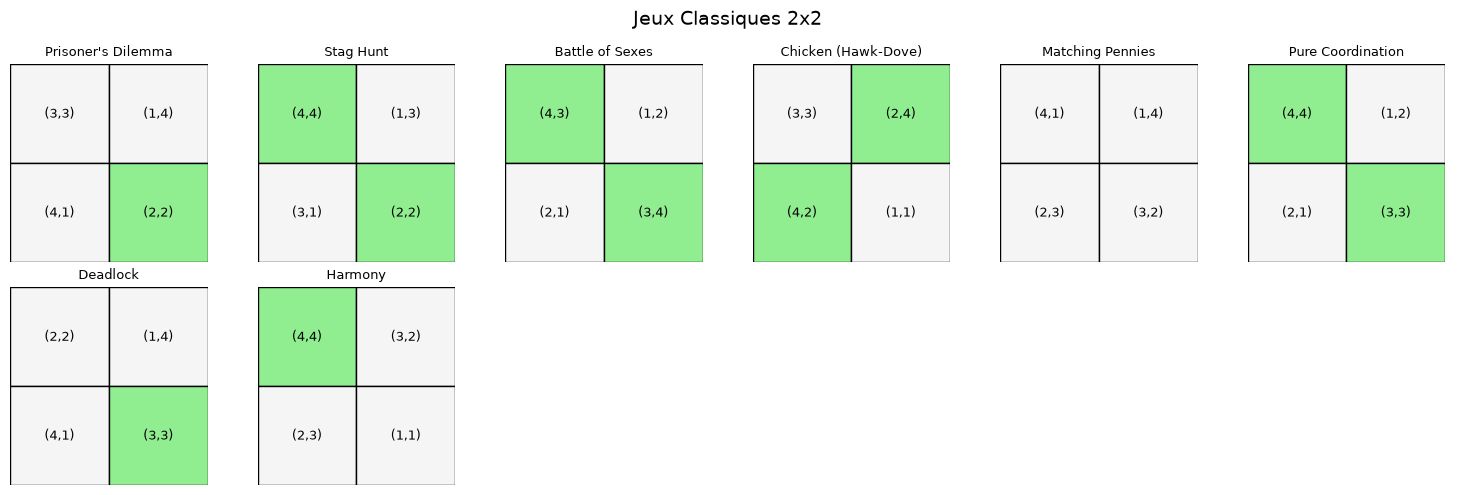

In [11]:
def get_row_preference_type(game: OrdinalGame) -> str:
    """
    Determine le type de preference du joueur Ligne.
    
    Basee sur la position du meilleur (4) et pire (1) resultat.
    """
    rp = game.row_payoffs
    pos_4 = rp.index(4)  # Position du meilleur
    pos_1 = rp.index(1)  # Position du pire
    
    # Encoder: position de 4 (0-3) et position de 1 (0-3)
    return f"{pos_4}_{pos_1}"

def visualize_games_grid(games: List[OrdinalGame], title: str = "Jeux 2x2"):
    """
    Visualise un ensemble de jeux dans une grille.
    """
    n = len(games)
    cols = min(6, n)
    rows = (n + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
    if rows == 1 and cols == 1:
        axes = np.array([[axes]])
    elif rows == 1:
        axes = axes.reshape(1, -1)
    elif cols == 1:
        axes = axes.reshape(-1, 1)
    
    for idx, game in enumerate(games):
        r, c = idx // cols, idx % cols
        ax = axes[r, c]
        
        A, B = game.to_matrices()
        eq = find_pure_nash(game)
        
        # Dessiner la matrice
        for i in range(2):
            for j in range(2):
                is_nash = (i, j) in eq
                color = '#90EE90' if is_nash else '#F5F5F5'
                rect = patches.Rectangle((j, 1-i), 1, 1, 
                                          facecolor=color, edgecolor='black')
                ax.add_patch(rect)
                ax.text(j+0.5, 1.5-i, f"({A[i,j]},{B[i,j]})", 
                       ha='center', va='center', fontsize=9)
        
        ax.set_xlim(0, 2)
        ax.set_ylim(0, 2)
        ax.set_aspect('equal')
        ax.axis('off')
        ax.set_title(game.name if game.name else f"Game {idx+1}", fontsize=9)
    
    # Cacher les axes vides
    for idx in range(n, rows * cols):
        r, c = idx // cols, idx % cols
        axes[r, c].axis('off')
    
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

# Visualiser les jeux classiques
classic_list = list(CLASSIC_GAMES.values())
visualize_games_grid(classic_list, "Jeux Classiques 2x2")

### Interpretation : Grille des jeux classiques

La visualisation montre les 8 jeux classiques avec leurs structures d'equilibre :

**Cellules vertes** = equilibres de Nash purs

**Patterns visuels** :
- **Un seul Nash** (PD, Deadlock, Harmony) : Une seule cellule verte - comportement previsible
- **Deux Nash diagonaux** (Stag Hunt, BoS, Pure Coordination) : Deux cellules vertes sur la diagonale
- **Deux Nash anti-diagonaux** (Chicken) : Deux cellules vertes hors diagonale
- **Aucun Nash** (Matching Pennies) : Aucune cellule verte - equilibre mixte uniquement

> **Remarque pedagogique** : Cette representation visuelle permet d'identifier immediatement le "type" d'un jeu en regardant simplement la position des cellules vertes.

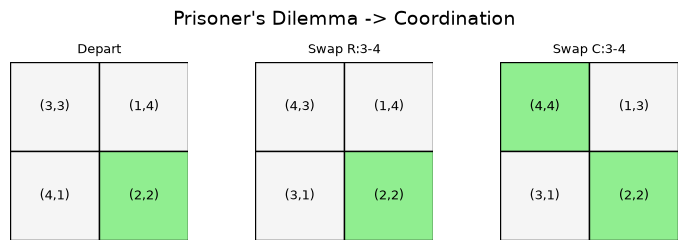

In [12]:
# Visualiser la transformation PD -> Stag Hunt -> Harmony
def show_transformation_chain(start_game: OrdinalGame, 
                               swaps: List[Tuple[str, int, int]],
                               title: str = "Transformation"):
    """
    Visualise une chaine de transformations.
    
    Args:
        start_game: Jeu de depart
        swaps: Liste de (player, rank1, rank2) ou player est 'R' ou 'C'
    """
    import copy
    games = [copy.deepcopy(start_game)]
    current = start_game
    
    for player, r1, r2 in swaps:
        if player == 'R':
            current = apply_row_swap(current, r1, r2)
        else:
            current = apply_col_swap(current, r1, r2)
        games.append(current)
    
    # Nommer les etapes
    for i, g in enumerate(games):
        if i == 0:
            g.name = f"Depart"
        else:
            p, r1, r2 = swaps[i-1]
            g.name = f"Swap {p}:{r1}-{r2}"
    
    visualize_games_grid(games, title)

# Transformation: Prisoner's Dilemma -> plus cooperatif
pd = CLASSIC_GAMES["Prisoner's Dilemma"]

# Swap 3-4 pour Row: (D,C) devient moins attirant que (C,C)
# Swap 3-4 pour Col: meme chose
show_transformation_chain(
    pd,
    [('R', 3, 4), ('C', 3, 4)],
    "Prisoner's Dilemma -> Coordination"
)

### Que montrent ces transformations ?

La visualisation précédente illustre comment le Dilemme du Prisonnier se transforme progressivement en un jeu de coordination :

**Étape 1** : Swap R:3-4
- Le joueur Ligne préfère maintenant la coopération mutuelle (C,C) à l'exploitation (D,C)
- Cela supprime l'incitation à "tricher" quand l'autre coopère

**Étape 2** : Swap C:3-4
- Le joueur Colonne fait de même
- Le jeu devient **symétrique** avec (C,C) comme meilleur résultat pour tous

**Résultat final** : Un jeu de type Stag Hunt où :
- Deux équilibres : (C,C) et (D,D)
- (C,C) est Pareto-optimal et préféré par tous
- Le problème n'est plus le "dilemme" mais la **confiance** pour atteindre le bon équilibre

## 7. Familles de jeux

Les jeux 2x2 peuvent etre regroupes en **familles** basees sur leur structure stratégique.

In [13]:
def has_dominant_strategy(game: OrdinalGame, player: int) -> bool:
    """
    Verifie si un joueur a une strategie dominante.
    """
    A, B = game.to_matrices()
    M = A if player == 0 else B.T
    
    # Strategie 0 domine 1 ?
    dom_0 = all(M[0, j] >= M[1, j] for j in range(2))
    # Strategie 1 domine 0 ?
    dom_1 = all(M[1, j] >= M[0, j] for j in range(2))
    
    return dom_0 or dom_1

def classify_game_family(game: OrdinalGame) -> str:
    """
    Classifie un jeu dans une famille.
    
    Familles:
    - DOMINANT: Les deux joueurs ont une strategie dominante
    - ASSURANCE: Un Nash Pareto-optimal, un Nash Pareto-domine
    - COORDINATION: Deux Nash purs, pas de dominance
    - CONFLICT: Interets opposes (ex: zero-sum like)
    - MIXED_ONLY: Pas de Nash pur
    """
    eq = find_pure_nash(game)
    n_eq = len(eq)
    
    dom_row = has_dominant_strategy(game, 0)
    dom_col = has_dominant_strategy(game, 1)
    
    if dom_row and dom_col:
        return "DOMINANT"
    elif n_eq == 0:
        return "MIXED_ONLY"
    elif n_eq == 1:
        return "SINGLE_NASH"
    elif n_eq == 2:
        # Coordination ou anti-coordination ?
        # Coordination: equilibres sur la diagonale (0,0) et (1,1)
        # Anti-coordination: equilibres hors diagonale (0,1) et (1,0)
        if (0, 0) in eq and (1, 1) in eq:
            return "COORDINATION"
        elif (0, 1) in eq and (1, 0) in eq:
            return "ANTI_COORDINATION"
        else:
            return "TWO_NASH"
    else:
        return "MULTI_NASH"

# Classifier les jeux classiques
print("Classification des jeux classiques en familles:")
print("=" * 50)

for name, game in CLASSIC_GAMES.items():
    family = classify_game_family(game)
    eq = find_pure_nash(game)
    print(f"{name:25} -> {family:20} (Nash: {eq})")

Classification des jeux classiques en familles:
Prisoner's Dilemma        -> DOMINANT             (Nash: [(1, 1)])
Stag Hunt                 -> COORDINATION         (Nash: [(0, 0), (1, 1)])
Battle of Sexes           -> COORDINATION         (Nash: [(0, 0), (1, 1)])
Chicken                   -> ANTI_COORDINATION    (Nash: [(0, 1), (1, 0)])
Matching Pennies          -> MIXED_ONLY           (Nash: [])
Pure Coordination         -> COORDINATION         (Nash: [(0, 0), (1, 1)])
Deadlock                  -> DOMINANT             (Nash: [(1, 1)])
Harmony                   -> DOMINANT             (Nash: [(0, 0)])


### Interpretation : Classification des jeux classiques

L'algorithme de classification place chaque jeu dans une famille basee sur deux critères :
1. La presence de stratégies dominantes
2. La position des equilibres de Nash (diagonale ou hors diagonale)

**Résultats cles** :

| Jeu | Famille | Explication |
|-----|---------|-------------|
| **Prisoner's Dilemma** | DOMINANT | Defaire domine pour les deux joueurs |
| **Deadlock** | DOMINANT | Comme PD mais equilibre est Pareto-optimal |
| **Harmony** | DOMINANT | Cooperer domine pour les deux joueurs |
| **Stag Hunt** | COORDINATION | Deux Nash sur diagonale, pas de dominance |
| **Battle of Sexes** | COORDINATION | Deux Nash sur diagonale, préférences asymetriques |
| **Pure Coordination** | COORDINATION | Deux Nash sur diagonale, préférences symetriques |
| **Chicken** | ANTI_COORDINATION | Deux Nash hors diagonale (0,1) et (1,0) |
| **Matching Pennies** | MIXED_ONLY | Aucun Nash pur, conflit total |

> **Note** : La distinction COORDINATION vs ANTI_COORDINATION est fondamentale. Dans les jeux de coordination, les joueurs veulent etre "ensemble" (même stratégie). Dans les jeux d'anti-coordination, ils veulent etre "différents".

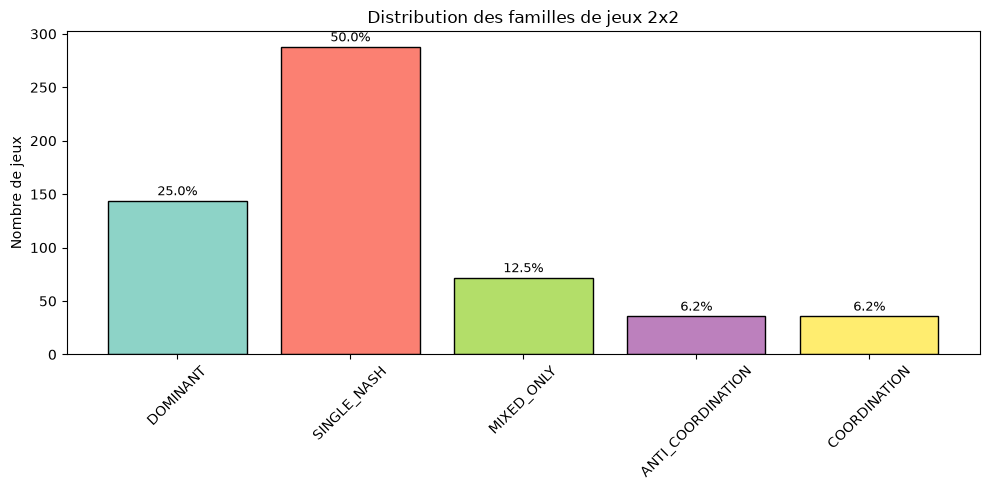

In [14]:
# Distribution des familles dans tous les jeux
family_counts = {}
for game in all_games:
    family = classify_game_family(game)
    family_counts[family] = family_counts.get(family, 0) + 1

# Visualisation
fig, ax = plt.subplots(figsize=(10, 5))

families = list(family_counts.keys())
counts = [family_counts[f] for f in families]
colors = plt.cm.Set3(np.linspace(0, 1, len(families)))

bars = ax.bar(families, counts, color=colors, edgecolor='black')

ax.set_ylabel('Nombre de jeux')
ax.set_title('Distribution des familles de jeux 2x2')
ax.tick_params(axis='x', rotation=45)

# Ajouter les pourcentages
for bar, count in zip(bars, counts):
    pct = 100 * count / 576
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            f'{pct:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### Interprétation de la distribution des familles

Le graphique révèle la répartition structurelle des jeux 2x2 :

**Points clés** :
- **SINGLE_NASH** est la famille la plus représentée (~50%) - un seul équilibre de Nash pur détermine le jeu
- **COORDINATION** et **ANTI_COORDINATION** ensemble représentent les ~12.5% avec 2 Nash
- **MIXED_ONLY** (~12.5%) sont les jeux de pur conflit sans Nash pur
- **DOMINANT** (~25%) : les deux joueurs ont une stratégie dominante - famille distincte de SINGLE_NASH

Cette distribution n'est pas aléatoire : elle reflète la structure combinatoire des préférences ordinales sur 4 cellules.

### 11.2. Exercice 2 : Cartographie des voisins d'un jeu classique

Choisissez un jeu classique (par exemple **Deadlock** ou **Harmony**) et construisez un **portrait complet** de ses 6 voisins dans le graphe des swaps : famille, equilibres de Nash, issues Pareto-optimales. Comparez l'**efficacite sociale** de chaque voisin avec le jeu original — identifiez le(s) voisin(s) Pareto-superieurs.

**Contexte pedagogique** : Cette analyse revele la **frontiere de viabilite** d'un jeu classique. Par exemple, Deadlock a un Nash unique (1,1) de gain social 6 : certains de ses voisins peuvent offrir un equilibre a gain social superieur (en devenant Coordination ou Anti-Coordination). C'est la base de la **théorie du design institutionnel** : modifier le contexte pour transformer le Nash en equilibre desirable.

**Indice 1 (generation systématique des 6 voisins)** :
- Utilisez les fonctions `apply_row_swap(game, r1, r2)` et `apply_col_swap(game, r1, r2)` pour les 3 paires `(1,2)`, `(2,3)`, `(3,4)` — soit 6 appels au total
- Pour un portrait structure : stockez le résultat dans une liste de tuples `(swap_label, voisin)` ou `swap_label = f"ROW_{r1}-{r2}"` par exemple
- Pattern : `voisins = [(f"ROW_{r1}-{r2}", apply_row_swap(game, r1, r2)) for r1, r2 in [(1,2), (2,3), (3,4)]] + [(f"COL_{r1}-{r2}", apply_col_swap(game, r1, r2)) for r1, r2 in [(1,2), (2,3), (3,4)]]`

**Indice 2 (analyse multi-critères par voisin)** :
- Pour chaque voisin, calculez 3 mesures : `classify_game_family()`, `find_pure_nash()`, `find_pareto_optimal()`
- La **comparaison Pareto** : pour chaque voisin, verifiez si son Nash est dans ses issues Pareto-optimales — si non, le voisin est dans un "dilemme" similaire au PD
- Outil utile : pour Deadlock `find_pareto_optimal` donne `[(0, 1), (1, 0), (1, 1)]` — le Nash `(1, 1)` est Pareto-optimal

**Indice 3 (synthese comparative)** :
- Identifiez quel(s) swap(s) transforme un DOMINANT (Deadlock, Harmony) en COORDINATION ou ANTI_COORDINATION : c'est l'**opération de redesign**
- Comparez le **gain social** : pour chaque voisin, calculez `sum(gains_nash)` et trouvez le maximum parmi les 6 voisins
- Pour Deadlock, le Nash `(1,1)=(3,3)` a un gain social de **6** ; cherchez les voisins ou ce gain augmente

In [15]:
def portrait_voisins(game: OrdinalGame) -> list:
    # TODO etudiant : implementer le portrait complet des 6 voisins
    # Etape 1 : calculer les 6 voisins avec apply_row_swap et apply_col_swap pour (1,2), (2,3), (3,4)
    # Etape 2 : pour chaque voisin, calculer famille, Nash purs, Pareto-optimal
    # Etape 3 : comparer l'efficacite sociale de chaque voisin avec le jeu original
    # Indice : la fonction find_pareto_optimal est definie en section 8
    return []  # TODO etudiant : remplacer

# jeu_choisi = CLASSIC_GAMES["Deadlock"]
# resultats = portrait_voisins(jeu_choisi)
print("Exercice a completer : cartographie des voisins")

Exercice a completer : cartographie des voisins


## 8. Efficacite sociale : Pareto

Un concept important est l'**efficacite de Pareto** : une issue est Pareto-optimale si aucune autre issue n'ameliore un joueur sans degrader l'autre.

In [16]:
def find_pareto_optimal(game: OrdinalGame) -> List[Tuple[int, int]]:
    """
    Trouve les issues Pareto-optimales.
    """
    A, B = game.to_matrices()
    pareto = []
    
    for i in range(2):
        for j in range(2):
            is_pareto = True
            for i2 in range(2):
                for j2 in range(2):
                    if (i2, j2) == (i, j):
                        continue
                    # (i2, j2) domine-t-il (i, j) ?
                    if A[i2, j2] >= A[i, j] and B[i2, j2] >= B[i, j]:
                        if A[i2, j2] > A[i, j] or B[i2, j2] > B[i, j]:
                            is_pareto = False
                            break
                if not is_pareto:
                    break
            if is_pareto:
                pareto.append((i, j))
    
    return pareto

def analyze_social_efficiency(game: OrdinalGame):
    """
    Analyse l'efficacite sociale d'un jeu.
    """
    eq = find_pure_nash(game)
    pareto = find_pareto_optimal(game)
    A, B = game.to_matrices()
    
    print(f"\n{game.name}")
    print("=" * 40)
    game.display()
    
    print(f"\nEquilibres de Nash purs: {eq}")
    print(f"Issues Pareto-optimales: {pareto}")
    
    # Nash est-il Pareto-optimal ?
    for e in eq:
        is_pareto = e in pareto
        status = "Pareto-optimal" if is_pareto else "Pareto-DOMINE"
        print(f"  Nash {e}: {status} (gains: {A[e]}, {B[e[0], e[1]]})")

# Analyser les jeux classiques
for name in ["Prisoner's Dilemma", "Stag Hunt", "Chicken", "Battle of Sexes"]:
    analyze_social_efficiency(CLASSIC_GAMES[name])


Prisoner's Dilemma

Prisoner's Dilemma
      C0        C1
R0  (3,3)    (1,4)
R1  (4,1)    (2,2)

Equilibres de Nash purs: [(1, 1)]
Issues Pareto-optimales: [(0, 0), (0, 1), (1, 0)]
  Nash (1, 1): Pareto-DOMINE (gains: 2, 2)

Stag Hunt

Stag Hunt
      C0        C1
R0  (4,4)    (1,3)
R1  (3,1)    (2,2)

Equilibres de Nash purs: [(0, 0), (1, 1)]
Issues Pareto-optimales: [(0, 0)]
  Nash (0, 0): Pareto-optimal (gains: 4, 4)
  Nash (1, 1): Pareto-DOMINE (gains: 2, 2)

Chicken (Hawk-Dove)

Chicken (Hawk-Dove)
      C0        C1
R0  (3,3)    (2,4)
R1  (4,2)    (1,1)

Equilibres de Nash purs: [(0, 1), (1, 0)]
Issues Pareto-optimales: [(0, 0), (0, 1), (1, 0)]
  Nash (0, 1): Pareto-optimal (gains: 2, 4)
  Nash (1, 0): Pareto-optimal (gains: 4, 2)

Battle of Sexes

Battle of Sexes
      C0        C1
R0  (4,3)    (1,2)
R1  (2,1)    (3,4)

Equilibres de Nash purs: [(0, 0), (1, 1)]
Issues Pareto-optimales: [(0, 0), (1, 1)]
  Nash (0, 0): Pareto-optimal (gains: 4, 3)
  Nash (1, 1): Pareto-optimal (g

### Le Dilemme du Prisonnier : l'exception qui confirme la règle

L'analyse de Pareto revele pourquoi le Dilemme du Prisonnier occupe une place si speciale en théorie des jeux :

| Jeu | Nash | Pareto-optimal ? | Conflit individuel/collectif ? |
|-----|------|------------------|-------------------------------|
| PD | (D,D) | NON | OUI - Le coeur du dilemme |
| Stag Hunt | (S,S) et (H,H) | (S,S) OUI, (H,H) NON | Partiel - Un Nash est bon |
| Chicken | (H,D) et (D,H) | Tous deux OUI | NON |
| BoS | (O,O) et (F,F) | Tous deux OUI | NON |

**L'unicite du PD** : C'est le seul jeu classique ou :
1. L'equilibre de Nash existe et est unique
2. Cet equilibre est Pareto-domine
3. Les deux joueurs ont une stratégie dominante

Cette combinaison créé le "dilemme" : chaque joueur fait ce qui est individuellement rationnel, mais le résultat collectif est sous-optimal pour TOUS.

**Implications** :
- Les marches sans regulation peuvent mener a des résultats sous-optimaux
- La cooperation necessite des mécanismes externes (contrats, reputation, institutions)
- Le simple fait de "communiquer" ne suffit pas (engagement non credible)

### Résumé visuel : Nash vs Pareto

Voici un tableau récapitulatif des résultats précédents :

| Jeu | Nash (gains) | Pareto-optimal ? | Somme des gains Nash | Meilleur Pareto possible |
|-----|--------------|------------------|---------------------|--------------------------|
| **PD** | (D,D) = (2,2) | ❌ NON | 4 | (C,C) = (3,3) → 6 |
| **Stag Hunt** | (S,S) = (4,4) | ✅ OUI | 8 | 8 (optimal !) |
| **Stag Hunt** | (H,H) = (2,2) | ❌ NON | 4 | 8 (perte de 50%) |
| **Chicken** | (H,D) = (4,2) | ✅ OUI | 6 | 6 (pas mieux) |
| **Chicken** | (D,H) = (2,4) | ✅ OUI | 6 | 6 (pas mieux) |
| **BoS** | Les deux Nash | ✅ OUI | 7 chacun | Aucune amélioration possible |

**Observation** : Dans Chicken et BoS, les équilibres de Nash sont Pareto-optimaux. Le problème n'est pas l'inefficacité mais la **coordination** - quel équilibre choisir ?

### Observation cle

Le **Dilemme du Prisonnier** est le seul jeu classique dont l'equilibre de Nash **unique** est **Pareto-domine**.

Attention a la nuance : la *Chasse au Cerf* (Stag Hunt) possede elle aussi un equilibre Pareto-domine -- (H,H)=(2,2), domine par (S,S)=(4,4). Mais Stag Hunt compte **deux** equilibres de Nash purs, et le second, (S,S)=(4,4), est Pareto-optimal : les joueurs peuvent donc se coordonner sur un bon equilibre. Le PD, lui, n'a qu'**un seul** equilibre, (D,D)=(2,2), et celui-ci est Pareto-domine par (C,C)=(3,3) -- il n'y a nulle part ou fuir. C'est cette combinaison (Nash unique + Nash Pareto-domine + strategies strictement dominantes, voir le tableau ci-dessus) qui cree veritablement le "dilemme" : la rationalite individuelle mene a un résultat collectivement sous-optimal, sans equilibre meilleur vers lequel se coordonner.

## 9. Du 576 au quotient 144 : dériver, pas recopier

Les sections 1 à 8 **dérivent** les 576 jeux ordinaux par énumération, mais **citent** deux nombres sans les calculer : le quotient à 144 classes et le « tore à 37 trous » de Robinson et Goforth. Ces deux nombres circulent partout sans dérivation — or une constante recopiée n'est pas un résultat.

Cette section dérive tout ce qui est **dérivable sans le livre**, par calcul exhaustif sur l'univers fini :

1. **le 144** : le nombre de classes sous renommage des stratégies, obtenu comme 576/4 parce que le renommage agit **librement** — plus une constante recopiée, une conséquence prouvée ;
2. **le 78** : les classes à échange des joueurs près, retrouvées indépendamment (croisement avec la classification classique de Rapoport-Guyer) ;
3. **les signatures d'équilibres** du quotient (18 jeux sans équilibre pur, 108 avec un seul, 18 avec deux) ;
4. **le graphe des swaps sur le quotient** : connexe, 6-régulier, 432 arêtes — le « se déplacer dans l'espace des jeux » de GameTheory-03b survit au quotient.

Et il établit honnêtement la frontière : **aucune** des notions naturelles testées ici (orbites, arêtes) ne produit 37. La dérivation du tore exige la construction du livre (un complexe de dimension 2, pas un simple comptage) : ce point précis reste une dette ouverte, documentée en section 6.

**Prérequis internes** : section 3 (les swaps comme générateurs), section 5 (structure de Nash). Voir aussi GameTheory-03f pour le versant morphismes.

### 9.1. L'univers des 576 jeux, reconstruit

Un jeu ordinal 2×2 ne contient **aucun paiement numérique** : chaque joueur range les quatre cases de préférée (niveau 1) à rejetée (niveau 4). Pour un joueur, attribuer les niveaux 1-4 aux quatre cases, c'est choisir une **permutation** — il y en a 4! = 24. Les deux joueurs choisissent indépendamment : 24 x 24 = 576 jeux. C'est la construction du notebook socle, reconduite ici pour que tout ce qui suit soit auto-porteur.

In [17]:
from itertools import permutations

# Une preference = niveaux 1..4 des 4 cases, lues dans l'ordre TL, TR, BL, BR.
# Niveau 1 = case preferee du joueur.
TL, TR, BL, BR = 0, 1, 2, 3
NOMS_CASES = ["TL", "TR", "BL", "BR"]

prefs_joueur = list(permutations(range(1, 5)))
print(f"Permutations d'un joueur : {len(prefs_joueur)}")

# Un jeu = (preference du joueur Ligne, preference du joueur Colonne)
jeux = [(a, b) for a in prefs_joueur for b in prefs_joueur]
print(f"Univers des jeux ordinaux 2x2 : {len(jeux)}")

Permutations d'un joueur : 24
Univers des jeux ordinaux 2x2 : 576


**Interprétation.** Les 576 tombent d'une multiplication triviale (24 x 24) — c'est bien une dérivation, et le notebook socle la possède déjà. Le nombre que la série cite **sans** dériver est le suivant : deux jeux qui ne diffèrent que par les **noms** des stratégies (appeler la première ligne « coopérer » plutôt que « dévier ») sont le même jeu. Combien de jeux distincts reste-t-il quand on identifie ces renommages ?

### 9.2. Le renommage des stratégies : une action de groupe, et elle est libre

Renommer les stratégies, c'est permuter les deux lignes, ou les deux colonnes, ou les deux. Ces quatre opérations forment un groupe G = S2 x S2 (ordre 4) qui **agit** sur les 576 jeux. Le nombre de classes est le nombre d'orbites. Deux façons de le compter :

- **l'énumération** : construire les orbites et les compter ;
- **l'argument structurel** : si l'action est *libre* — aucun jeu n'est invariant par un renommage non trivial — alors chaque orbite a exactement |G| = 4 éléments et le nombre de classes est 576/4 = 144.

Le code teste les deux, et la confrontation des tailles d'orbites à {4} **est** la preuve de liberté.

In [18]:
def perm_lignes(jeu):
    # Echanger les deux lignes : TL<->BL et TR<->BR
    (a, b) = jeu
    return (tuple([a[BL], a[BR], a[TL], a[TR]]), tuple([b[BL], b[BR], b[TL], b[TR]]))

def perm_colonnes(jeu):
    # Echanger les deux colonnes : TL<->TR et BL<->BR
    (a, b) = jeu
    return (tuple([a[TR], a[TL], a[BR], a[BL]]), tuple([b[TR], b[TL], b[BR], b[BL]]))

G = [
    lambda g: g,                                              # identite
    perm_lignes,
    perm_colonnes,
    lambda g: perm_colonnes(perm_lignes(g)),                  # les deux
]

orbites, vus, tailles = [], set(), {}
for jeu in jeux:
    if jeu in vus:
        continue
    orb = {tuple(f(jeu)) for f in G}
    vus |= orb
    orbites.append(min(orb))
    tailles[len(orb)] = tailles.get(len(orb), 0) + 1

print(f"Nombre d'orbites (classes de renommage) : {len(orbites)}")
print(f"Repartition des tailles d'orbites : {tailles}")
assert all(t == 4 for t in tailles), "action non libre : stabilisateur non trivial !"
print("Action libre : aucune orbite de taille < 4 -> 576 / 4 = 144")

Nombre d'orbites (classes de renommage) : 144
Repartition des tailles d'orbites : {4: 144}
Action libre : aucune orbite de taille < 4 -> 576 / 4 = 144


**Interprétation.** Le 144 n'est plus une constante recopiée : c'est **576 divisé par 4**, et la division est légitimée par une propriété vérifiée à l'exhaustif — toutes les orbites ont exactement 4 éléments. D'où vient cette liberté ? Un renommage non trivial déplace au moins une case ; pour qu'un jeu soit invariant, il faudrait que le joueur attribue le **même** niveau à deux cases — impossible, puisque chaque niveau 1-4 apparaît exactement une fois. La liberté n'est pas un hasard de comptage, elle est structuelle : c'est la stricte ordinalité de l'univers.

### 9.3. Ce que contient le quotient : les signatures d'équilibres

Une fois les 144 classes obtenues, la question naturelle : à quoi ressemblent-elles ? La notion la plus discriminante disponible sans théorie additionnelle est la **signature d'équilibres de Nash purs** — quelles cases sont des meilleures réponses mutuelles. Sur un jeu 2×2 strictement ordinal, chaque joueur a exactement deux meilleures réponses (une par stratégie de l'adversaire) ; l'intersection des deux motifs donne les équilibres purs.

In [19]:
def meilleures_reponses(jeu):
    a, b = jeu
    brA, brB = set(), set()
    for col in (0, 1):
        # Le joueur Ligne choisit sa ligne, le joueur Colonne fixe la colonne
        valeurs = {l: a[l * 2 + col] for l in (0, 1)}
        mini = min(valeurs.values())
        for l in (0, 1):
            if valeurs[l] == mini:
                brA.add((l, col))
    for lig in (0, 1):
        valeurs = {c: b[lig * 2 + c] for c in (0, 1)}
        mini = min(valeurs.values())
        for c in (0, 1):
            if valeurs[c] == mini:
                brB.add((lig, c))
    return brA, brB

def ne_purs(jeu):
    brA, brB = meilleures_reponses(jeu)
    return tuple(sorted(brA & brB))

signature = {}
for rep in orbites:
    ne = ne_purs(rep)
    signature.setdefault(len(ne), 0)
    signature[len(ne)] += 1

print("Nombre d'equilibres de Nash purs, par classe du quotient :")
for k in sorted(signature):
    print(f"  {k} equilibre(s) pur(s) : {signature[k]} classes")
print(f"Total : {sum(signature.values())}")

Nombre d'equilibres de Nash purs, par classe du quotient :
  0 equilibre(s) pur(s) : 18 classes
  1 equilibre(s) pur(s) : 108 classes
  2 equilibre(s) pur(s) : 18 classes
Total : 144


**Interprétation.** La répartition 18 / 108 / 18 (aucun, un, deux équilibres purs) est loin d'être uniforme : la grande masse des jeux 2×2 a exactement un équilibre pur, et les extrêmes — les jeux sans équilibre pur (tout mixte, comme certaines variantes de Matching Pennies ordinal) et les jeux à deux équilibres purs (coordination, bataille des sexes) — sont symétriquement rares. Aucune classe n'a trois équilibres purs ou plus : sur un univers strictement ordinal 2×2, c'est impossible, et l'exhaustivité le certifie.

### 9.4. Validation croisée : l'échange des joueurs retrouve le 78

La classification classique des jeux 2×2 ordinaux (Rapoport et Guyer, 1966) compte **78** jeux distincts. Leur notion d'équivalence est plus grossière que la nôtre : en plus du renommage des stratégies, ils identifient l'**échange des deux joueurs** (le jeu vu par A et le même jeu vu par B sont le même). Si notre pipeline est correct, étendre le groupe d'une involution d'échange doit faire tomber les 144 à exactement 78 — une validation croisée indépendante du livre de Robinson-Goforth.

In [20]:
def echange_joueurs(jeu):
    # A prend la place de B : la matrice est transposee et les preferences permutees
    (a, b) = jeu
    transpose = [TL, BL, TR, BR]
    na = [b[transpose[i]] for i in range(4)]
    nb = [a[transpose[i]] for i in range(4)]
    return (tuple(na), tuple(nb))

orbites_etendues, vus2 = [], set()
for jeu in orbites:
    if jeu in vus2:
        continue
    orb = {tuple(f(jeu)) for f in G} | {tuple(f(echange_joueurs(jeu))) for f in G}
    vus2 |= orb
    orbites_etendues.append(min(orb))

print(f"Orbites du groupe etendu (renommage + echange des joueurs) : {len(orbites_etendues)}")

Orbites du groupe etendu (renommage + echange des joueurs) : 78


**Interprétation.** 78, retrouvé par le calcul seul. Ce nombre n'était pas annoncé dans notre série : il vient de la classification de Rapoport-Guyer, et le fait que notre pipeline — construit uniquement à partir de la définition des 576 et du renommage — le reproduise est un test de cohérence bien plus fort qu'une vérification de boucle (un pipeline faux aurait peu de chances de tomber sur le nombre historique). Le couple (144, 78) est maintenant **dérivé** : le premier par action du renommage, le second par extension aux échanges de joueurs.

### 9.5. Le graphe des swaps survit au quotient

GameTheory-03b fait « bouger » les jeux avec les six swaps adjacents (R12, R23, R34 pour un joueur, C12, C23, C34 pour l'autre). Une question que le quotient rend naturelle : ce graphe de déplacement reste-t-il cohérent sur les 144 classes — et surtout, reste-t-il **connexe** ? Si un renommage pouvait déconnecter l'espace, la notion même de « voisinage de jeux » du socle serait un artefact du nommage.

In [21]:
def swaps_adjacents(jeu):
    # Les 6 generateurs : echanger deux niveaux adjacents d'un joueur.
    a, b = list(jeu[0]), list(jeu[1])
    resultat = {}
    for (n1, n2, nom) in [(1, 2, "R12"), (2, 3, "R23"), (3, 4, "R34")]:
        na = a[:]
        i, j = na.index(n1), na.index(n2)
        na[i], na[j] = na[j], na[i]
        resultat[nom] = (tuple(na), jeu[1])
    for (n1, n2, nom) in [(1, 2, "C12"), (2, 3, "C23"), (3, 4, "C34")]:
        nb = b[:]
        i, j = nb.index(n1), nb.index(n2)
        nb[i], nb[j] = nb[j], nb[i]
        resultat[nom] = (jeu[0], tuple(nb))
    return resultat

def canonique(jeu):
    return min(tuple(f(jeu)) for f in G)

representants = {canonique(jeu) for jeu in jeux}
depart = min(representants)
frontiere, visites = [depart], {depart}
while frontiere:
    jeu = frontiere.pop()
    for voisin in swaps_adjacents(jeu).values():
        c = canonique(voisin)
        if c not in visites:
            visites.add(c)
            frontiere.append(c)

degres = {}
for rep in representants:
    voisins = {canonique(v) for v in swaps_adjacents(rep).values()} - {rep}
    degres[len(voisins)] = degres.get(len(voisins), 0) + 1

print(f"Connexite du graphe des swaps sur le quotient : {len(visites)} / {len(representants)} classes atteintes")
print(f"Distribution des degres : {degres}")
print(f"Arêtes du quotient : {sum(k * v for k, v in degres.items()) // 2}")

Connexite du graphe des swaps sur le quotient : 144 / 144 classes atteintes
Distribution des degres : {6: 144}
Arêtes du quotient : 432


**Interprétation.** Le quotient est connexe et **exactement 6-régulier** : chaque classe a ses six voisins de swap, distincts deux à deux, comme chaque jeu avant quotient. C'est plus qu'une connexité : le quotient préserve la structure locale complète du graphe de déplacement — les swaps commutent au renommage (faire un swap puis renommer égale renommer puis le swap correspondant), donc le voisinage se transporte sans perte. La géographie de GameTheory-03b (l'espace des jeux comme paysage que l'on parcourt case par case) n'est pas un artefact des noms : elle vit sur les 144 classes elles-mêmes.

### 9.6. Le tore à 37 trous : la frontière de ce que le calcul établit

Reste le troisième nombre cité sans dérivation : le « tore à 37 trous ». Ce notebook le cherche et **ne le trouve pas dans les notions naturellement calculables** sur l'univers fini :

| Notion testée | Résultat du calcul |
|---|---|
| Classes de renommage (section 9.2) | 144 |
| Classes à échange de joueurs près (section 9.4) | 78 |
| Arêtes du graphe de swaps quotient | 432 |

Aucune ne rend 37 — et ce n'est pas un échec du code, c'est une information : le 37 de Robinson-Goforth ne compte ni des classes de jeux, ni des équilibres, ni des arêtes. Il vit dans la **construction du livre** : un complexe de dimension 2 (l'espace des préférences de chaque joueur, dont les faces sont remplies, puis leur produit), pas dans un comptage sur les jeux eux-mêmes. Dériver le 37 exige la définition exacte de ce complexe — c'est-à-dire le texte source.

**Dette réduite, dette assumée** : sur les trois nombres de la section 3 de #12207, ce notebook en dérive deux (144, et par extension 78) et établit que le troisième (37) n'est pas atteignable par comptage sur l'univers des jeux. Toute base Lean future sur ces nombres (cf. #12205) doit s'appuyer sur les dérivations présentes — et sur le PDF pour le tore, exactement comme le demandait l'EPIC.

### 9.7. Exemple résolu : localiser un jeu nommé dans le quotient

Avant les exercices, un exemple complet sur un jeu célèbre. Le Dilemme du Prisonnier ordinal : chaque joueur préfère dévier quoi que fasse l'autre (DC > CC > DD > CD). Encodons la version où Ligne est le joueur A et Colonnes le joueur B, puis trouvons sa classe canonique et sa signature.

In [22]:
# Dilemme du Prisonnier ordinal.
# Pour Ligne : BL (D,C) = 1, TL (C,C) = 2, BR (D,D) = 3, TR (C,D) = 4
# Pour Colonne : TR (C,D) = 1, TL (C,C) = 2, BR (D,D) = 3, BL (D,C) = 4
pd_ligne = [2, 4, 1, 3]   # niveaux TL, TR, BL, BR
pd_colonne = [2, 1, 4, 3]
pd = (tuple(pd_ligne), tuple(pd_colonne))

assert pd in set(jeux), "encodage invalide"
classe_pd = canonique(pd)
print(f"Forme canonique du DP dans le quotient : {classe_pd}")
nom_case = {(0, 0): "TL", (0, 1): "TR", (1, 0): "BL", (1, 1): "BR"}
ne_pd = ne_purs(pd)
print(f"Equilibres de Nash purs du DP : {[nom_case[i] for i in ne_pd]}")
print(f"Position dans le quotient : classe #{sorted(representants).index(classe_pd) + 1} / {len(representants)}")

Forme canonique du DP dans le quotient : ((1, 3, 2, 4), (4, 3, 2, 1))
Equilibres de Nash purs du DP : ['BR']
Position dans le quotient : classe #72 / 144


**Interprétation.** L'unique équilibre pur du Dilemme du Prisonnier tombe en BR — la défection mutuelle — et c'est bien l'involution du dilemme : les deux joueurs préfèrent TL (2 contre 3) mais y jouent leur pire réponse. Le jeu nommé est désormais un **point daté du quotient** : une classe parmi 144, avec sa signature. C'est le geste que la section suivante demande de généraliser.

### 9.8. Exercices — dériver le quotient

Les trois exercices suivent le fil du notebook : prouver par une autre voie, cartographier, vérifier une propriété de structure. Chacun a son indice ; le notebook s'exécute intégralement même sans complétion.

#### Exercice 1 — Le 144 par le lemme de Burnside

L'énumération donne 144 classes. Retrouvez ce nombre **sans construire les orbites**, par le lemme de Burnside : le nombre d'orbites d'un groupe G agissant sur un ensemble E est la moyenne des points fixes, (1/|G|) * somme des |Fix(g)| pour g dans G.

**Indice** : pour chaque élément non trivial de G, comptez les jeux invariants. La liberté de l'action (section 9.2) prédit ce que doit valoir chaque |Fix(g)| — le résultat doit retomber sur 144.

In [23]:
def points_fixes(f):
    # Nombre de jeux invariants par l'operation f.
    # Etape 1 : iterer sur jeux, tester si f(jeu) == jeu
    # Etape 2 : compter
    result = None  # TODO etudiant
    print("Exercice a completer")
    return result

# Etape 3 : appliquer Burnside sur les 4 elements de G
# orbites_burnside = (points_fixes(id) + points_fixes(perm_lignes) + points_fixes(perm_colonnes) + points_fixes(composee)) / 4
burnside = None  # TODO etudiant
print("Exercice a completer : attendu 144")

Exercice a completer : attendu 144


#### Exercice 2 — Cartographier quatre jeux célèbres

Le Dilemme du Prisonnier est localisé en section 9.7. Placez de même le Jeu de la Poule (Chicken), la Chasse au Cerf (Stag Hunt) et la Bataille des Sexes : encodez les préférences ordinales de chacun, trouvez leur classe canonique et leur signature d'équilibres purs.

**Indice** : trois encodages suffisent à remplir le tableau — deux jeux peuvent partager une même classe si leur différence n'est qu'un renommage. Vérifiez vos encodages avec l'assertion d'appartenance à l'univers.

In [24]:
def encoder_et_localiser(nom, niveaux_ligne, niveaux_colonne):
    # Retourne (classe canonique, nombre d'equilibres purs, positions) d'un jeu encode.
    jeu = (tuple(niveaux_ligne), tuple(niveaux_colonne))
    assert jeu in set(jeux), f"encodage invalide pour {nom}"
    # Etape 1 : forme canonique via canonique(jeu)
    # Etape 2 : signature via ne_purs(jeu)
    print("Exercice a completer")
    return None  # TODO etudiant

# Poule : pour chaque joueur, la pire issue est la double confrontation (DD pire),
# mieux vaut céder quand l'autre tient, mieux vaut tenir quand l'autre cède.
# Chasse au Cerf : le cerf partagé est le meilleur, le lièvre seul est sûr,
# le lièvre quand l'autre chasse le cerf est médiocre, rien du tout est moyen.
# Bataille des Sexes : les deux coordinations sont préférées à la décoordination,
# mais chacun préfère sa propre coordination.
carte = None  # TODO etudiant
print("Exercice a completer : attendu un dict nom -> (classe, signature)")

Exercice a completer : attendu un dict nom -> (classe, signature)


#### Exercice 3 — Le renommage et les swaps commutent-ils ?

La section 9.5 affirme que les swaps « commutent au renommage », ce qui explique le 6-régulier du quotient. Vérifiez-le explicitement : pour chaque opération de renommage non triviale et chaque swap, comparez renommer-puis-swapper et swapper-puis-renommer.

**Indice** : après renommage des lignes, le swap « R12 » du jeu renommé correspond au même échange de niveaux — les swaps opèrent sur les **niveaux**, pas sur les positions. Testez l'égalité des deux chemins sur quelques jeux, puis concluez sur la structure du voisinage.

In [25]:
def commutent(f_renommage, nom_swap, jeu):
    # Teste si renommer-puis-swapper et swapper-puis-renommer restent dans la meme orbite.
    # Etape 1 : chemin 1 = renommer puis swapper
    # Etape 2 : chemin 2 = swapper puis renommer
    # Etape 3 : comparer via canonique()
    print("Exercice a completer")
    return None  # TODO etudiant

resultat = None  # TODO etudiant
print("Exercice a completer : attendu True sur un echantillon (ou la limite exacte)")

Exercice a completer : attendu True sur un echantillon (ou la limite exacte)


### 9.9. Résumé de la dérivation

- **144 n'est plus une citation** : c'est 576/4, et la légitimité de la division (action libre du renommage, toutes les orbites de taille 4) est vérifiée à l'exhaustif (section 9.2) et par Burnside (exercice 9.8.1).
- **78 est retrouvé indépendamment** (section 9.4) : la classification de Rapoport-Guyer tombe du même pipeline, validation croisée externe.
- **Le quotient est un espace de travail complet** : signatures d'équilibres 18/108/18 (section 9.3), graphe de swaps connexe et 6-régulier (section 9.5) — la géographie de la série survit au quotient.
- **La frontière est écrite** : le « tore à 37 trous » n'est pas dérivable par comptage sur les jeux (section 9.6) ; il exige la construction du livre. La dette de vérification de #12207 est réduite de deux tiers, précisément délimitée pour la suite.

#### Sources, attribution et dettes de vérification

- Robinson, D. & Goforth, D. (2005). *The Topology of the 2×2 Games*. Routledge — source du 144 et du tore ; le 144 est ici **dérivé**, le tore reste **rapporté**.
- Rapoport, A. & Guyer, M. (1966). A taxonomy of 2x2 games. *General Systems* 11 — le 78 historique, retrouvé par le calcul (section 9.4).
- EPIC #12207, section 3 (dettes de vérification) — le présent notebook paie les items dérivables sans le texte source et délimite le reste.
- Les swaps adjacents comme générateurs : GameTheory-03b ; le versant morphismes : GameTheory-03f ; les murs et chambres : GameTheory-03c.

## 10. Resume

### Concepts cles

| Concept | Description |
|---------|-------------|
| **Representation ordinale** | Rangs 1-4 au lieu de gains cardinaux |
| **Swap adjacent** | Echange de deux rangs consecutifs |
| **Graphe des jeux** | Jeux comme noeuds, swaps comme aretes |
| **Famille de jeux** | Classification par structure de Nash |
| **Efficacite de Pareto** | Issue non dominee |

### Familles principales

| Famille | Exemple | Caractéristique |
|---------|---------|------------------|
| **DOMINANT** | Prisoner's Dilemma | Stratégie dominante pour tous |
| **COORDINATION** | Battle of Sexes, Stag Hunt | Deux Nash sur diagonale |
| **ANTI-COORDINATION** | Chicken | Deux Nash hors diagonale |
| **MIXED_ONLY** | Matching Pennies | Aucun Nash pur |

### Points importants

1. Les jeux 2x2 forment un espace **structure** avec des connexions topologiques
2. Un **petit changement** de préférences peut transformer radicalement la nature d'un jeu
3. La **classification** aide a comprendre quand la cooperation emerge ou echoue

## 11. Exercices

Cette section rassemble **3 exercices progressifs** sur l'exploration topologique des jeux 2x2 ; trois exercices supplémentaires sur la dérivation du quotient (Burnside, cartographie, commutation) figurent en **section 9.8**. Chaque exercice s'appuie sur les fonctions de manipulation de swaps (`apply_row_swap`, `apply_col_swap`) et les classifieurs structurels (`classify_game_family`, `find_pure_nash`, `find_pareto_optimal`) définis dans les sections précédentes.

**Contexte d'ensemble** : les exos 11.1 et 11.2 explorent le **voisinage local** d'un jeu (ses 6 voisins immediats). L'exo 11.3 passe a l'echelle **globale** : classifier automatiquement tous les 576 jeux 2x2 par leur structure de Nash, puis cartographier la **distribution** des familles dans l'espace topologique.

Note de convention : les cellules de stub utilisent `return []  # TODO etudiant` (pas de `raise NotImplementedError`, règle C.1). Le notebook s'execute de bout en bout même sans completer les exercices.

### 11.3. Exercice 3 : Classification automatique des jeux 2x2 par structure

A partir des 576 jeux generes par `generate_all_ordinal_games()`, utilisez `classify_by_nash_structure()` pour produire un **recensement complet** : combien de jeux ont 0, 1, 2, 3 ou 4 equilibres de Nash purs ? Visualisez la distribution sous forme de **bar chart horizontal** et identifiez visuellement les **3 anomalies structurelles** (les catégories rares ou absentes).

**Contexte pedagogique** : Cette analyse globale revele la **structure combinatoire** des préférences ordinales sur 4 cellules. Le résultat attendu (0 Nash: ~12.5%, 1 Nash: ~75%, 2 Nash: ~12.5%, 3+ Nash: 0%) reflete une **asymetrie profonde** : les jeux 2x2 ne sont **pas uniformement distribues** dans l'espace topologique — la majorite convergent vers un seul comportement d'equilibre, seuls les cas degeneres en ont 0 ou 2+.

**Indice 1 (utilisation de la fonction de classification globale)** :
- `classify_by_nash_structure(games_set)` retourne un dict `{'0_nash': [...], '1_nash': [...], '2_nash': [...], '3_nash': [...], '4_nash': [...]}`
- Pour compter : `{k: len(v) for k, v in catégories.items()}` — vous obtenez un dict simple `{catégorie: nombre}`
- Pour les pourcentages : divisez chaque compte par `len(games_set)` (= 576 par construction) et multipliez par 100

**Indice 2 (visualisation matplotlib)** :
- Pour un bar chart horizontal : `plt.barh(catégories, counts)` ou vertical : `plt.bar(catégories, counts)`
- Ajoutez les labels : `plt.xlabel('Nombre de jeux')`, `plt.ylabel('Nombre de Nash purs')`, `plt.title('Distribution des equilibres dans les 576 jeux 2x2')`
- Pour annoter les barres avec les pourcentages : boucle `for i, (cat, count) in enumerate(...)` puis `plt.text(count + 5, i, f'{100*count/576:.1f}%', va='center')`

**Indice 3 (interpretation structurelle)** :
- Identifiez pourquoi **3_nash = 0** : si 3 cellules d'une matrice 2x2 sont des equilibres de Nash, la symetrie des meilleures réponses force la 4ᵉ a l'etre aussi (donc 4_nash) — argument formel verifiable par enumeration
- Identifiez pourquoi **4_nash = 0** aussi : pour qu'une cellule soit un Nash, les deux stratégies du joueur oppose doivent etre sous-optimales — sur 4 cellules, c'est structurellement impossible en 2x2
- Question bonus : pourquoi la majorite des jeux (~75%) convergent-ils vers **1_nash** ? (indice : la structure des préférences ordinales rend les "ex-aequo" sur les meilleures réponses rares)

In [26]:
def classify_and_visualize_nash_distribution(games_set: Set[OrdinalGame]) -> Dict[str, int]:
    """
    Classifier tous les jeux par structure de Nash et visualiser la distribution.
    
    Args:
        games_set: Ensemble de jeux 2x2 (576 par construction depuis generate_all_ordinal_games)
    
    Returns:
        Dict {categorie: nombre} avec categories parmi '0_nash', '1_nash', '2_nash', '3_nash', '4_nash'
    """
    # TODO etudiant : implementer la classification + visualisation
    # Etape 1 : appeler classify_by_nash_structure(games_set) pour obtenir les categories
    # Etape 2 : construire le dict {cat: len(games_list) for cat, games_list in categories.items()}
    # Etape 3 : creer un bar chart avec plt.barh() et annoter les pourcentages
    # Etape 4 : retourner le dict {cat: count}
    # Indice : 576 = 24 permutations Row x 24 permutations Col ; resultat attendu 0:72, 1:432, 2:72, 3:0, 4:0
    return {}  # TODO etudiant : remplacer

# distribution = classify_and_visualize_nash_distribution(all_games)
# print(distribution)
print("Exercice a completer : classification et visualisation des 576 jeux 2x2")

Exercice a completer : classification et visualisation des 576 jeux 2x2


### A retenir

L'espace des jeux 2x2 est une **structure topologique** (tore), pas un catalogue de cas isoles :

| Résultat | Valeur |
|----------|--------|
| Jeux 2x2 ordinaux | **576** (4! x 4!) |
| Distincts (equivalence stratégique) | **144** |
| Classes (symetrie joueur) | **78** |
| Nash : 0, 1, 2, 3+ | 12,5% / **75%** / 12,5% / 0% |

**Insight central** : **deux swaps** de préférences suffisent à transformer un Dilemme du Prisonnier en Stag Hunt ou Chicken. Cette proximite topologique modelise comment les institutions (contrats, reputation, loi) modifient les incitations vers la cooperation.

**Unicite du PD** : seul jeu classique ou l'equilibre de Nash unique (D,D)=(2,2) est **Pareto-domine** par (C,C)=(3,3) - la signature structurelle du conflit rationalite individuelle vs collective.


**Lien avec la formalisation Lean**

La classification de Robinson-Goforth des jeux 2x2 et la topologie du tore des ordinaux s'appuient sur les structures `Game2x2` et `NormalFormGame` définies dans [`lean_game_defs/Basic.lean`](lean_game_defs/Basic.lean). Les équivalences entre classes (dominance stricte, équilibres de Nash purs) sont reliées aux prédicats `strictlyDominates1` et `isPureNashEquilibrium` de [`lean_game_defs/Nash.lean`](lean_game_defs/Nash.lean).

***

**Notebook précédent**: [GameTheory-02-NormalForm-Python](GameTheory-02-NormalForm-Python.ipynb)  
**Notebook suivant**: [GameTheory-04-NashEquilibrium-Python](GameTheory-04-NashEquilibrium-Python.ipynb)